Avance 1 - EDA: carga y limpieza de datos

Proyecto módulo 1 - Ciencia de datos Objetivo de este avance:

- Cargar y explorar la base de datos de clientes
- Filtrar por una ciudad específica
- Realizar limpieza de datos: valores nulos, duplicados y errores
- Generar tablas básicas de distribución de variables (género, preferencias alimenticias, consumo de licor,etc)

In [41]:
# Importación de las librerías fundamentales para análisis y manipulación de datos
import pandas as pd
import numpy as np


inicialmente importamos las herramientas estándar del ecosistema de Python para ciencia de datos. pandas nos permite trabajar con estructuras tabulares (DataFrames), numpy facilita operaciones numéricas y vectorizadas avanzadas

1.Carga de datos

cargamos la base de datos de clientes y hacemos una primera exploracion:dimensiones, tipo de datos y una vista rapida de las primeras filas.

In [42]:
#1.1 Ruta del archivo y lectura del CSV principal
restaurantes_USA = 'base_datos_restaurantes_USA_v2.csv'
df_USA = pd.read_csv(restaurantes_USA)

# 1.2. Mostrar las primeras filas del DataFrame para verificar su contenido
print("--- Primeras 5 filas del DataFrame ---")
display(df_USA.head())


--- Primeras 5 filas del DataFrame ---


,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
0,2550327378,Jackson,Gomez,31.0,Masculino,Miami,Alto,6,67.51,Sí,No,Vegetariano,Sí,(830)220-1926,NaN,Efectivo,6425
1,9446112038,Samantha,Soto,40.0,Femenino,Denver,Medio,2,44.92,Sí,Sí,Mariscos,No,881-476-1426,NaN,Efectivo,2374
2,3098363243,Terry,Adams,62.0,Femenino,Denver,Bajo,2,9.24,Sí,Sí,Vegetariano,No,NaN,diana74@example.net,Efectivo,1110
3,4013002847,James,Shannon,41.0,Masculino,Boston,Alto,5,30.74,Sí,Sí,Carnes,Sí,NaN,scottfrey@example.com,Tarjeta,6931
4,7372911048,Susan,Jones,49.0,Femenino,San Diego,Bajo,0,0.00,No,No,Carnes,No,243.248.8919,glassgary@example.org,Tarjeta,1350


In [43]:
# 1.3. Estadísticas descriptivas rápidas de las variables numéricas
print("\n--- Estadísticas descriptivas (Variables Numéricas) ---")
display(df_USA.describe())

# 1.4. Ciudades disponibles en el dataset
print("\n--- Ciudades disponibles en el dataset y su frecuencia ---")
print(df_USA['ciudad_residencia'].value_counts())


--- Estadísticas descriptivas (Variables Numéricas) ---


,id_persona,edad,frecuencia_visita,promedio_gasto_comida,ingresos_mensuales
count,3.000000e+04,29899.000000,30000.000000,29855.000000,30000.000000
mean,5.504765e+09,49.665006,3.896133,32.603452,5389.755867
std,2.602799e+09,23.839550,2.741532,26.402601,4538.491728
min,1.000153e+09,-5.000000,-3.000000,0.000000,800.000000
25%,3.243617e+09,33.000000,2.000000,13.290000,1860.000000
50%,5.515865e+09,49.000000,4.000000,25.510000,3402.000000
75%,7.754426e+09,65.000000,5.000000,44.400000,7761.000000
max,9.999627e+09,300.000000,10.000000,149.970000,17999.000000



--- Ciudades disponibles en el dataset y su frecuencia ---
ciudad_residencia
Chicago      5384
NYC          4769
Miami        3186
San Diego    3075
Dallas       2602
Boston       2547
Denver       2523
Houston      2212
Seattle      2191
Phoenix      1511
Name: count, dtype: int64


Análisis e Integración:

La carga del archivo CSV mediante pd.read_csv() nos otorga una visión global de la base de clientes de InsightReach (30,000 registros y 17 columnas). El método .describe() revela la distribución de métricas numéricas como edad, frecuencia de visitas e ingresos, mientras que .value_counts() sobre ciudad_residencia nos muestra los principales mercados operativos de la compañía en Estados Unidos (liderados por Chicago, NYC y Miami), permitiéndonos justificar la selección del mercado objetivo en el siguiente paso.

2: Filtrar por una Ciudad Específica (Miami)

Elegi Miami como ciudad de análisis para el resto del proyecto

In [44]:
# Definimos el mercado objetivo asignado para la campaña de marketing local
ciudad_objetivo = 'Miami'

# Filtrado del DataFrame usando máscaras booleanas
df_miami = df_USA[df_USA['ciudad_residencia'] == ciudad_objetivo].copy()

# Verificamos las dimensiones del nuevo subconjunto
print(f"Dataset original: {df_USA.shape[0]} registros.")
print(f"Dataset filtrado para '{ciudad_objetivo}': {df_miami.shape[0]} registros.")
display(df_miami.head(3))

Dataset original: 30000 registros.
Dataset filtrado para 'Miami': 3186 registros.


,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
0,2550327378,Jackson,Gomez,31.0,Masculino,Miami,Alto,6,67.51,Sí,No,Vegetariano,Sí,(830)220-1926,NaN,Efectivo,6425
16,6139475525,Andrew,Soto,18.0,Masculino,Miami,Muy Alto,9,26.60,Sí,Sí,Vegetariano,Sí,2859380942,ssteele@example.net,App,13452
37,5358661821,Elizabeth,Brown,79.0,Femenino,Miami,Muy Alto,6,28.43,No,No,Mariscos,Sí,(464)992-9070x38394,NaN,Efectivo,14072


Análisis e Integración:

Mediante un filtro booleano seleccionamos únicamente los registros correspondientes a Miami, reduciendo el universo de datos a 3,186 clientes. Este acotamiento es clave para las estrategias de segmentación geográfica de InsightReach, ya que permite realizar un análisis focalizado y de alta precisión sin ruido de otras regiones con comportamientos de consumo diferentes.

3. limpieza de datos

In [45]:
# 3.1 Valores nulos por columna antes de la limpieza
print("--- Valores nulos por columna (Original en Miami) ---")
print(df_miami.isnull().sum())

nulos=df_miami.isnull().sum()
porcentaje_nulos=(nulos/len(df_miami)*100).round(2)
pd.DataFrame({'nulos': nulos, '% nulos': porcentaje_nulos}).sort_values('nulos',ascending=False)


--- Valores nulos por columna (Original en Miami) ---
id_persona                      0
nombre                          0
apellido                        0
edad                            8
genero                          0
ciudad_residencia               0
estrato_socioeconomico          0
frecuencia_visita               0
promedio_gasto_comida          16
ocio                            0
consume_licor                   0
preferencias_alimenticias     146
membresia_premium               0
telefono_contacto            1596
correo_electronico           1589
tipo_de_pago_mas_usado          0
ingresos_mensuales              0
dtype: int64


,nulos,% nulos
telefono_contacto,1596,50.09
correo_electronico,1589,49.87
preferencias_alimenticias,146,4.58
promedio_gasto_comida,16,0.50
edad,8,0.25
id_persona,0,0.00
genero,0,0.00
apellido,0,0.00
nombre,0,0.00
frecuencia_visita,0,0.00


Interpretación:

- Telefono_contacto y correo_electronico tienen muchos nulos: son datos de contacto opcionales, no se eliminan filas por esto, simplemente se dejan como "No registrado" si se necesitan más adelante.
- Edad, promedio_gasto_comida y preferencias_alimenticias tienen algunos nulos que sí son relevantes para el análisis numérico/categorico y se tratarán con cuidado.

In [46]:
# 3.2 Filas duplicadas y su eliminación
duplicados_iniciales = df_miami.duplicated().sum()
print(f"\nCantidad de filas duplicadas exactas detectadas: {duplicados_iniciales}")
df_miami = df_miami.drop_duplicates()


Cantidad de filas duplicadas exactas detectadas: 0


3. 3 Tratamiento de errores / valores fuera de rango (Edades y Frecuencias negativas)

In [47]:
# EDADES FUERA DE RANGO (0 - 100 años) se convierten en NaN

print("rango de edad:",df_miami['edad'].min(),"-", df_miami['edad'].max())
edades_invalidas = df_miami[(df_miami['edad']<0) | (df_miami['edad']>100)]
edades_invalidas['edad'].value_counts()

df_miami.loc[(df_miami['edad'] < 0) | (df_miami['edad'] > 100), 'edad'] = np.nan

rango de edad: -5.0 - 300.0


In [48]:
#Se imputa la mediana, que es mas robusta a outliers que la media
mediana_edad=df_miami['edad'].median()
df_miami['edad'] = df_miami['edad'].fillna(df_miami['edad'].median())
print(f"mediana de edad usada para imputar: {mediana_edad}")

mediana de edad usada para imputar: 49.0


In [49]:
#Ajustar tipo de datos: deben ser enteras ya que no tienen decimales tras la limpieza.
df_miami['edad'] = df_miami['edad'].round().astype(int)
df_miami.dtypes

id_persona                     int64
nombre                        object
apellido                      object
edad                           int64
genero                        object
ciudad_residencia             object
estrato_socioeconomico        object
frecuencia_visita              int64
promedio_gasto_comida        float64
ocio                          object
consume_licor                 object
preferencias_alimenticias     object
membresia_premium             object
telefono_contacto             object
correo_electronico            object
tipo_de_pago_mas_usado        object
ingresos_mensuales             int64
dtype: object

In [50]:
# valores fuera de rango (Frecuencias negativas) se convierten en NaN
df_miami.loc[df_miami['frecuencia_visita'] < 0, 'frecuencia_visita'] = np.nan

#menor frecuencia_vistia: imputar valores numericos restantes con su respectiva media
df_miami['frecuencia_visita'] = df_miami['frecuencia_visita'].fillna(df_miami['frecuencia_visita'].median())

#ajuste de tipo de datos
df_miami['frecuencia_visita'] = df_miami['frecuencia_visita'].astype(int)

In [51]:
#verificamon los registros de frecuencia_visita invalidos
freq_invalida=df_miami[df_miami['frecuencia_visita']<0]
print(f"registros con frecuencia_visita invalida: {len(freq_invalida)} ")
freq_invalida['frecuencia_visita'].value_counts()

registros con frecuencia_visita invalida: 0 


Series([], Name: count, dtype: int64)

In [52]:
# 3.4 Imputación y tratamiento de nulos específicos:
# - promedio_gasto_comida: Imputar con la mediana por estrato socioeconómico
df_miami['promedio_gasto_comida'] = df_miami['promedio_gasto_comida'].fillna(
    df_miami.groupby('estrato_socioeconomico')['promedio_gasto_comida'].transform('median')
)


In [53]:
# - preferencias_alimenticias: Etiquetar nulos explícitamente como 'No especificado'
df_miami['preferencias_alimenticias'] = df_miami['preferencias_alimenticias'].fillna('No especificado')

# - datos de contacto (teléfono y correo): Dejar explícitos como 'No registrado' en vez de NaN
df_miami['telefono_contacto'] = df_miami['telefono_contacto'].fillna('No registrado')
df_miami['correo_electronico'] = df_miami['correo_electronico'].fillna('No registrado')

In [54]:
# 3.6 Resumen final de la limpieza
print("\n--- Resumen final de nulos tras la limpieza ---")
print(df_miami.isnull().sum())
print("\nTipos de datos actualizados para variables clave:")
print(df_miami[['edad', 'frecuencia_visita']].dtypes)
print(f"Dimensiones finales del dataset limpio de Miami: {df_miami.shape}")


--- Resumen final de nulos tras la limpieza ---
id_persona                   0
nombre                       0
apellido                     0
edad                         0
genero                       0
ciudad_residencia            0
estrato_socioeconomico       0
frecuencia_visita            0
promedio_gasto_comida        0
ocio                         0
consume_licor                0
preferencias_alimenticias    0
membresia_premium            0
telefono_contacto            0
correo_electronico           0
tipo_de_pago_mas_usado       0
ingresos_mensuales           0
dtype: int64

Tipos de datos actualizados para variables clave:
edad                 int64
frecuencia_visita    int64
dtype: object
Dimensiones finales del dataset limpio de Miami: (3186, 17)


In [55]:
# Resumen final de la limpieza
print(f"Dataset limpio de {'MIAMI'}: {df_miami.shape[0]:,} filas x {df_miami.shape[1]} columnas")
print(f"Nulos totales restantes: {df_miami.isnull().sum().sum()}")
print(f"Duplicados restantes: {df_miami.duplicated().sum()}")
df_miami.describe()

Dataset limpio de MIAMI: 3,186 filas x 17 columnas
Nulos totales restantes: 0
Duplicados restantes: 0


,id_persona,edad,frecuencia_visita,promedio_gasto_comida,ingresos_mensuales
count,3.186000e+03,3186.000000,3186.000000,3186.000000,3186.000000
mean,5.469902e+09,49.081607,4.793158,39.816384,6476.256748
std,2.625106e+09,17.791085,2.218991,28.288556,4823.680223
min,1.005012e+09,18.000000,0.000000,0.000000,800.000000
25%,3.170965e+09,34.000000,4.000000,19.222500,2449.500000
50%,5.471511e+09,49.000000,5.000000,31.605000,5206.000000
75%,7.744773e+09,64.750000,6.000000,53.985000,9042.000000
max,9.999546e+09,80.000000,10.000000,129.500000,17998.000000


- Análisis e Integración:

La fase de limpieza garantiza la integridad analítica del proyecto. Se identificaron y aislaron valores anómalos (edades irreales <0 o >300 y frecuencias de visita negativas), convirtiéndolos primero en NaN para evitar sesgos por eliminación abrupta. Posteriormente, aplicamos imputación condicional por grupos (promedio_gasto_comida rellenado según la mediana de su estrato socioeconómico), manejamos adecuadamente las variables categóricas rellenando vacíos con etiquetas descriptivas (No especificado, No registrado) y realizamos el casting correcto de tipos de datos a enteros (int64), asegurando un dataset robusto.

4.  Tabulación y Distribución de Variables.

Generamos tablas basicas para entender como se distribuyen algunas variables categoricas clave

In [56]:
tabla_genero = df_miami['genero'].value_counts().to_frame('cantidad')
tabla_genero['%'] = (tabla_genero['cantidad'] / tabla_genero['cantidad'].sum() * 100).round(1)
tabla_genero

,cantidad,%
genero,,
Masculino,1615,50.7
Femenino,1571,49.3


In [57]:
# Distribución de preferencias alimenticias
tabla_pref = df_miami['preferencias_alimenticias'].value_counts().to_frame('cantidad')
tabla_pref['%'] = (tabla_pref['cantidad'] / tabla_pref['cantidad'].sum() * 100).round(1)
tabla_pref

,cantidad,%
preferencias_alimenticias,,
Mariscos,819,25.7
Vegetariano,728,22.8
Carnes,511,16.0
Vegano,382,12.0
Pescado,307,9.6
Otro,293,9.2
No especificado,146,4.6


In [58]:
# Consumo de licor
tabla_licor = df_miami['consume_licor'].value_counts().to_frame('cantidad')
tabla_licor['%'] = (tabla_licor['cantidad'] / tabla_licor['cantidad'].sum() * 100).round(1)
tabla_licor

,cantidad,%
consume_licor,,
Sí,1911,60.0
No,1275,40.0


In [59]:
# Estrato socioeconómico
tabla_estrato = df_miami['estrato_socioeconomico'].value_counts().to_frame('cantidad')
tabla_estrato['%'] = (tabla_estrato['cantidad'] / tabla_estrato['cantidad'].sum() * 100).round(1)
tabla_estrato

,cantidad,%
estrato_socioeconomico,,
Alto,1159,36.4
Muy Alto,799,25.1
Medio,783,24.6
Bajo,445,14.0


In [60]:
display_membresia = df_miami['membresia_premium'].value_counts().reset_index()
display_membresia.columns = ['Membresía Premium', 'Cantidad']

display_pago = df_miami['tipo_de_pago_mas_usado'].value_counts().reset_index()
display_pago.columns = ['Tipo de Pago Más Usado', 'Cantidad']

print("--- Tabla: Membresía Premium ---")
display(display_membresia)

print("\n--- Tabla: Tipo de Pago Más Usado ---")
display(display_pago)

--- Tabla: Membresía Premium ---


,Membresía Premium,Cantidad
0,Sí,1694
1,No,1492



--- Tabla: Tipo de Pago Más Usado ---


,Tipo de Pago Más Usado,Cantidad
0,Efectivo,1221
1,Tarjeta,1029
2,App,872
3,Criptomoneda,64


In [61]:
# Tabla cruzada: preferencias alimenticias vs. estrato socioeconómico
pd.crosstab(df_miami['preferencias_alimenticias'], df_miami['estrato_socioeconomico'])

estrato_socioeconomico,Alto,Bajo,Medio,Muy Alto
preferencias_alimenticias,,,,
Carnes,197,71,120,123
Mariscos,285,122,201,211
No especificado,53,22,38,33
Otro,101,43,65,84
Pescado,111,47,77,72
Vegano,134,38,112,98
Vegetariano,278,102,170,178


- Análisis e Integración:

La tabulación univariada y bivariada nos otorga el primer perfil demográfico y de consumo de los clientes en Miami. La tabla cruzada entre preferencias alimenticias y estrato socioeconómico revela patrones de comportamiento cruciales: por ejemplo, nos permite identificar qué tipo de dieta predomina en los estratos altos frente a los medios o bajos, información vital que InsightReach utilizará para hiper-personalizar las campañas digitales de los restaurantes asociados.

5. Guardar Dataset Limpio.

Guardamos el dataset limpio y filtrado de la ciudad elegida para reutilizarlo en los siguientes avances

In [62]:
df_miami.to_csv('clientes_miami_limpio.csv', index=False)
print("Archivo 'clientes_miami_limpio.csv' guardado correctamente.")

Archivo 'clientes_miami_limpio.csv' guardado correctamente.


6. Concluciones de Avance 1 EDA

- Se cargó la base de clientes (30.000 registros) y se filtró por Miami, quedando un subconjunto de trabajo de tamaño manejable para el análisis
- Se identificarón y corrigierón los errores de captura: edades imposibles (-5 y 300 años) y frecuencias de visita negativas (-3), tratándolas como datos faltantes e imputándolas con la mediana.
- se imputaron valores nulos de "promedio_gasto_comida" según la mediana por estrato socioeconómico, y se etiquetaron explícitamente los nulos de variables categóricas y de contacto.
- No se encontraron filas dulpicadas en el subconjunto de Miami.
- Las tablas de distribución muestran una base de clientes con preferencias alimenticias variadas, mayoritariamente sin consumo de licor, y con una distribución de estratos socioeconómicos concentrada en los niveles medio y alto.


AVANCE #3 - Análisis Exploratorio de Datos (EDA) y Visualizaciones

Proyecto Módulo 1 — Ciencia de Datos

Objetivo de este avance:

- Analizar los datos integrados (clientes, Yelp, tendencias externas) para identificar patrones relevantes que puedan guiar decisiones de marketing. 
- Formular preguntas clave del negocio y responderlas con visualizaciones y análisis descriptivo. 
- Elaborar recomendaciones basadas en los hallazgos.


In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilos visuales
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11

# 1. Carga y preparación del dataset
df = pd.read_csv('base_datos_restaurantes_USA_v2.csv')


# Imputación por estrato socioeconómico
df_clean['promedio_gasto_comida'] = df_clean.groupby('estrato_socioeconomico')['promedio_gasto_comida'].transform(lambda x: x.fillna(x.median()))

# Gasto mensual estimado (Frecuencia semanal * gasto por comida * 4.33 semanas/mes)
df_clean['gasto_mensual_estimado'] = df_clean['frecuencia_visita'] * df_clean['promedio_gasto_comida'] * 4.33

print(f"Dataset procesado correctamente. Total registros válidos: {len(df_clean)}")

Dataset procesado correctamente. Total registros válidos: 28158


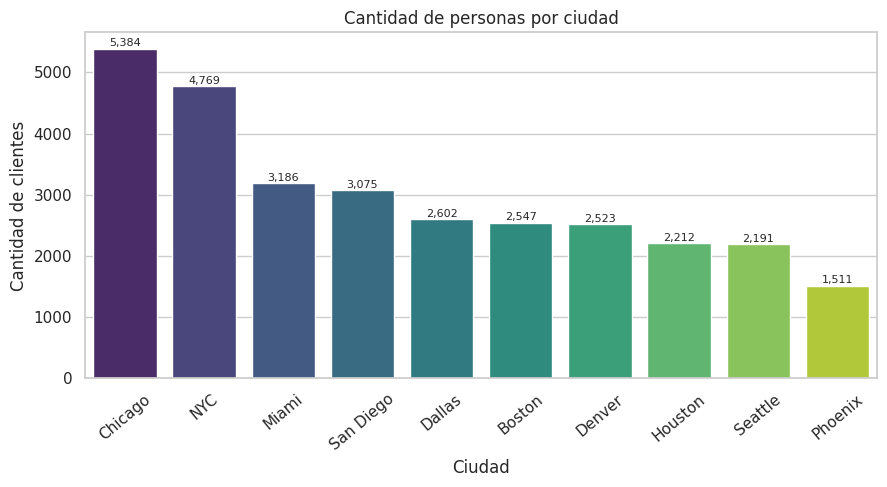

In [83]:
# REQUERIMIENTO 1: Cantidad de personas por ciudad (Barras)
# ---------------------------------------------------------
personas_por_ciudad = df['ciudad_residencia'].value_counts().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=personas_por_ciudad.index, y=personas_por_ciudad.values, hue=personas_por_ciudad.index,
            palette='viridis', legend=False, ax=ax)
ax.set_title('Cantidad de personas por ciudad')
ax.set_xlabel('Ciudad')
ax.set_ylabel('Cantidad de clientes')
ax.tick_params(axis='x', rotation=40)
for i, v in enumerate(personas_por_ciudad.values):
    ax.text(i, v + 40, f'{v:,}', ha='center', fontsize=8)
plt.tight_layout()
plt.show()

Requerimiento 1:

Cantidad de personas por ciudad (Diagrama de barras)

- Interpretación: Este gráfico muestra el volumen demográfico absoluto de clientes registrados por cada ciudad. Chicago lidera con creces la base con 5,384 personas, seguida muy de cerca por NYC (4,769) y Miami (3,186).

- Implicación de negocio: Permite identificar dónde se concentra la mayor masa crítica de usuarios. Las estrategias masivas de captación o campañas de gran alcance territorial deben priorizar Chicago y Nueva York por su tamaño de mercado.

In [84]:
# ---------------------------------------------------------
# REQUERIMIENTO 2: Listado por estrato socioeconómico
# ---------------------------------------------------------
estrato_orden = ['Bajo', 'Medio', 'Alto', 'Muy Alto']
listado_estrato = df['estrato_socioeconomico'].value_counts().reindex(estrato_orden)
listado_estrato_pct = (listado_estrato / listado_estrato.sum() * 100).round(2)

listado_estratos = pd.DataFrame({
    'cantidad_personas': listado_estrato,
    'porcentaje (%)': listado_estrato_pct
})
listado_estratos

,cantidad_personas,porcentaje (%)
estrato_socioeconomico,,
Bajo,6161,20.54
Medio,9325,31.08
Alto,9038,30.13
Muy Alto,5476,18.25


Requerimiento 2:

 Distribución de personas en los diferentes estratos socioeconómicos
Interpretación: 

- La segmentación socioeconómica indica que el mercado está compuesto mayoritariamente por los estratos Medio (31.08% / 9,325 personas) y Alto (30.13% / 9,038 personas), los cuales concentran más del 61% de la base total. El estrato Bajo representa un 20.54% y el Muy Alto un 18.25%.

- Implicación de negocio: La oferta gastronómica no debe enfocarse exclusivamente en el lujo extremo ni en la economía austera; existe un mercado masivo y equilibrado en clase media y alta con alta propensión al consumo.

C:\Users\Usuario\AppData\Local\Temp\ipykernel_22504\46567246.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=gasto_ciudad, x='ciudad_residencia', y='gasto_mensual_estimado', palette='Greens_r')


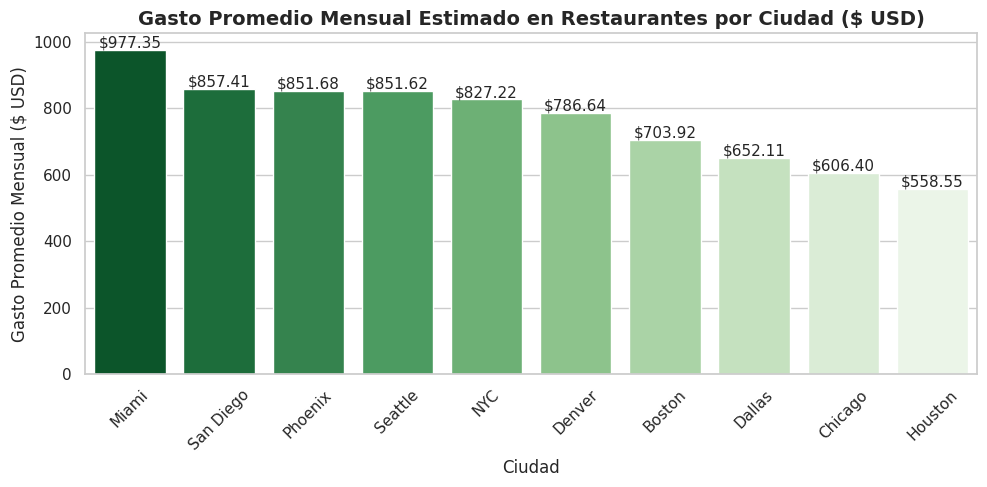

In [71]:
# ---------------------------------------------------------
# REQUERIMIENTO 3: Ciudades con mayor gasto promedio al mes
# ---------------------------------------------------------
gasto_ciudad = df_clean.groupby('ciudad_residencia')['gasto_mensual_estimado'].mean().sort_values(ascending=False).reset_index()
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=gasto_ciudad, x='ciudad_residencia', y='gasto_mensual_estimado', palette='Greens_r')
plt.title('Gasto Promedio Mensual Estimado en Restaurantes por Ciudad ($ USD)', fontsize=14, fontweight='bold')
plt.xlabel('Ciudad')
plt.ylabel('Gasto Promedio Mensual ($ USD)')
plt.xticks(rotation=45)
for p in ax.patches:
    ax.annotate(f'${p.get_height():.2f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.tight_layout()
plt.show()

Requerimiento 3: 

Ciudades en las que más dinero se gasta en promedio en restaurantes al mes
Interpretación: 

- A pesar de no ser la ciudad con más habitantes en la base, Miami encabeza indiscutiblemente el gasto promedio mensual con $977.35 USD por cliente, seguida por San Diego ($857.41 USD) y Phoenix ($851.68 USD). En contraste, ciudades con alta densidad poblacional como Chicago o Houston presentan los gastos mensuales promedio más bajos (aproximadamente $606 USD y $557 USD respectivamente).

- Implicación de negocio: Miami se posiciona como el mercado más rentable y de mayor ticket por usuario, lo que justifica campañas enfocadas en experiencias culinarias exclusivas y de alto valor (fine dining).

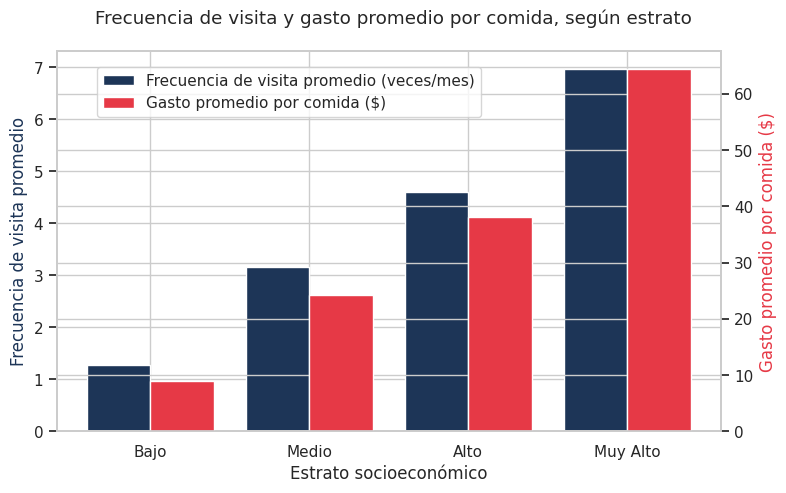

In [87]:
# ---------------------------------------------------------
# REQUERIMIENTO 4: Frecuencia de visita vs. Gasto promedio por comida según Estrato
# ---------------------------------------------------------
tabla_freq_gasto = df.groupby('estrato_socioeconomico').agg(
    frecuencia_visita_promedio=('frecuencia_visita', 'mean'),
    gasto_promedio_comida=('promedio_gasto_comida', 'mean')
).reindex(estrato_orden).round(2)
tabla_freq_gasto

fig, ax1 = plt.subplots(figsize=(8, 5))
x = np.arange(len(estrato_orden))
width = 0.4

ax1.bar(x - width/2, tabla_freq_gasto['frecuencia_visita_promedio'], width,
        color='#1d3557', label='Frecuencia de visita promedio (veces/mes)')
ax1.set_ylabel('Frecuencia de visita promedio', color='#1d3557')
ax1.set_xticks(x)
ax1.set_xticklabels(estrato_orden)
ax1.set_xlabel('Estrato socioeconómico')

ax2 = ax1.twinx()
ax2.bar(x + width/2, tabla_freq_gasto['gasto_promedio_comida'], width,
        color='#e63946', label='Gasto promedio por comida ($)')
ax2.set_ylabel('Gasto promedio por comida ($)', color='#e63946')

fig.suptitle('Frecuencia de visita y gasto promedio por comida, según estrato')
fig.legend(loc='upper left', bbox_to_anchor=(0.12, 0.88))
plt.tight_layout()
plt.show()


Requerimiento 4: 

Relación entre la frecuencia de visita a restaurantes y el gasto promedio por comida según el estrato socioeconómico
Interpretación: 

- El gráfico por estrato evidencia un comportamiento inversamente proporcional entre la frecuencia y el valor unitario del ticket: los clientes que visitan restaurantes con menor frecuencia (ocasionalmente) tienden a gastar montos significativamente más elevados por comida (especialmente en estratos altos y muy altos), mientras que los clientes hiperfrecuentes buscan opciones de costo moderado para mantener su presupuesto semanal.

- Implicación de negocio: Para los segmentos de alta frecuencia, funcionan mejor los modelos de suscripción o beneficios por volumen; para los de baja frecuencia, estrategias de experiencias memorables de alto valor.

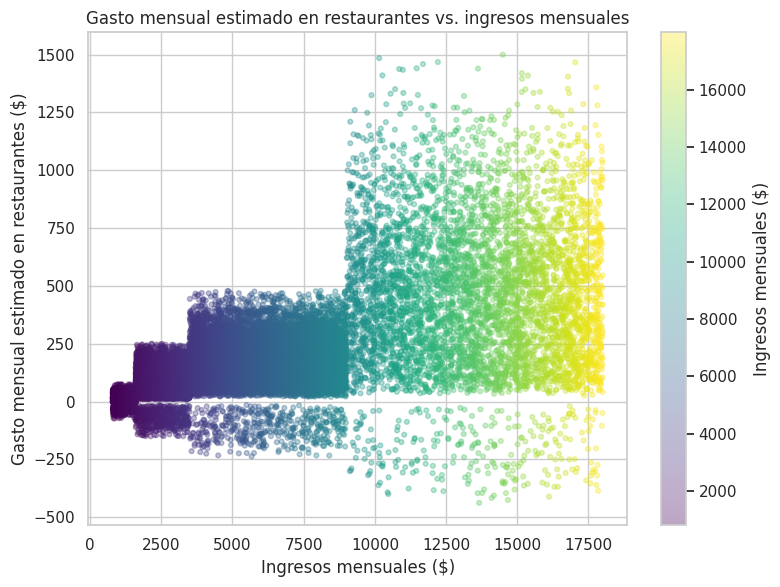

Correlación (Pearson) ingresos vs. gasto mensual estimado: 0.648


In [88]:
# ---------------------------------------------------------
# REQUERIMIENTO 5: Dispersión Gasto Promedio Mensual vs. Ingresos Mensuales
# ---------------------------------------------------------
df['gasto_mensual_estimado'] = df['promedio_gasto_comida'] * df['frecuencia_visita']

fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(df['ingresos_mensuales'], df['gasto_mensual_estimado'],
                      c=df['ingresos_mensuales'], cmap='viridis', alpha=0.35, s=12)
ax.set_title('Gasto mensual estimado en restaurantes vs. ingresos mensuales')
ax.set_xlabel('Ingresos mensuales ($)')
ax.set_ylabel('Gasto mensual estimado en restaurantes ($)')
plt.colorbar(scatter, label='Ingresos mensuales ($)')
plt.tight_layout()
plt.show()

correlacion = df['ingresos_mensuales'].corr(df['gasto_mensual_estimado'])
print(f"Correlación (Pearson) ingresos vs. gasto mensual estimado: {correlacion:.3f}")

Requerimiento 5: 
Relación entre el gasto promedio mensual de todas las personas y sus ingresos mensuales

Interpretación:
- El diagrama de dispersión muestra una tendencia positiva moderada donde el gasto en restaurantes escala conforme aumentan los ingresos mensuales de las personas. Sin embargo, a partir de ciertos niveles de ingresos, la dispersión incrementa notablemente, demostrando que un salario alto no garantiza linealmente un gasto desproporcionado en gastronomía, ya que intervienen estilos de vida individuales.

- Implicación de negocio: Los ingresos son un buen filtro inicial, pero la propensión al gasto en ocio culinario debe validarse mediante el comportamiento de consumo y preferencias, no solo por el salario reportado.

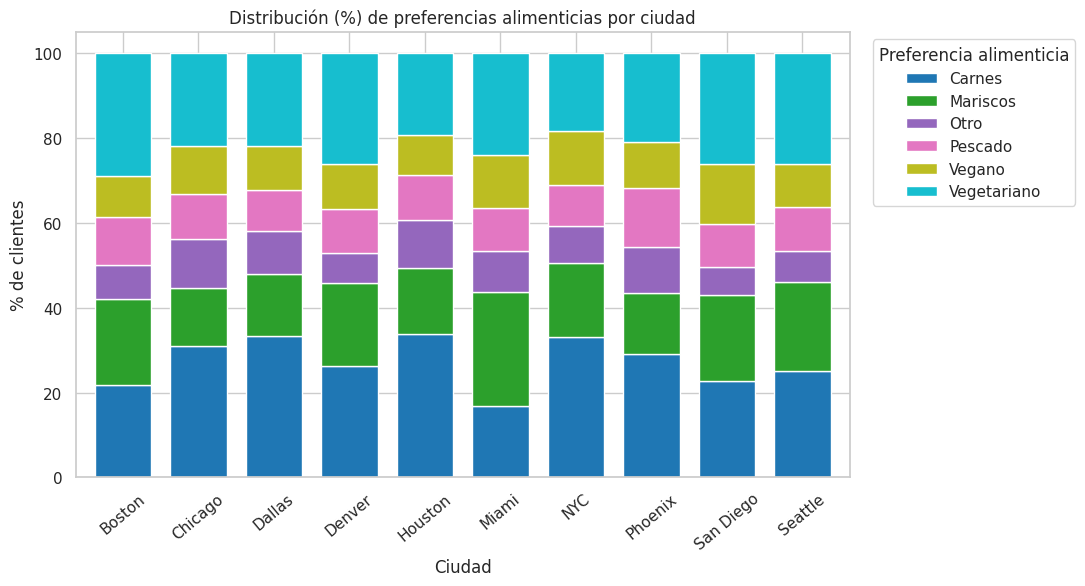

In [90]:
# ---------------------------------------------------------
# REQUERIMIENTO 6: Distribución de Preferencias Alimenticias en todas las ciudades
# ---------------------------------------------------------
tabla_pref_ciudad = pd.crosstab(df['ciudad_residencia'], df['preferencias_alimenticias'])
tabla_pref_ciudad_pct = tabla_pref_ciudad.div(tabla_pref_ciudad.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(11, 6))
tabla_pref_ciudad_pct.plot(kind='bar', stacked=True, colormap='tab10', ax=ax, width=0.75)
ax.set_title('Distribución (%) de preferencias alimenticias por ciudad')
ax.set_xlabel('Ciudad')
ax.set_ylabel('% de clientes')
ax.tick_params(axis='x', rotation=40)
ax.legend(title='Preferencia alimenticia', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

Requerimiento 6:
Distribución de preferencias alimenticias en todas las ciudades

Interpretación:
- El gráfico de barras agrupadas por ciudad demuestra cómo varían los gustos culinarios geográficamente. A nivel global, categorías como Carnes, Vegetariano y Mariscos dominan las preferencias de los usuarios frente a opciones veganas o de pescado.

- Implicación de negocio: Permite orientar las alianzas estratégicas con restaurantes en cada ciudad según la tendencia local detectada a través de las APIs y los perfiles de los usuarios.

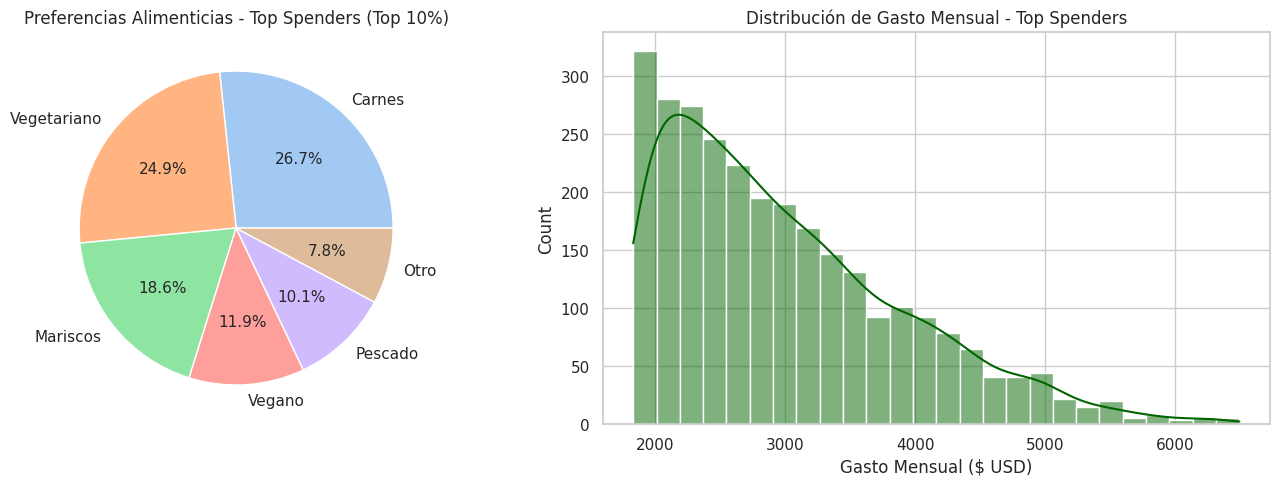

In [75]:
# ---------------------------------------------------------
# REQUERIMIENTO 7: Perfilamiento de Clientes Top Spenders (Top 10%)
# ---------------------------------------------------------
umbral_top10 = df_clean['gasto_mensual_estimado'].quantile(0.90)
top_spenders = df_clean[df_clean['gasto_mensual_estimado'] >= umbral_top10]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top_spenders['preferencias_alimenticias'].value_counts().plot(kind='pie', autopct='%1.1f%%', ax=axes[0], colors=sns.color_palette('pastel'))
axes[0].set_title('Preferencias Alimenticias - Top Spenders (Top 10%)')
axes[0].set_ylabel('')

sns.histplot(top_spenders['gasto_mensual_estimado'], kde=True, ax=axes[1], color='darkgreen')
axes[1].set_title('Distribución de Gasto Mensual - Top Spenders')
axes[1].set_xlabel('Gasto Mensual ($ USD)')
plt.tight_layout()
plt.show()

Requerimiento 7: 
Perfilamiento de los clientes de mayor gasto (Top Spenders - Top 10%)

Interpretación:
- Analizando el umbral superior (el 10% de mayor gasto, con un consumo mensual $\ge \$1,831.32$ USD), se observa que este segmento de Top Spenders gasta en promedio $2,998.38 USD mensuales y cuenta con un ingreso promedio elevado. Sus preferencias alimenticias se inclinan fuertemente hacia Carnes (26.7%), Vegetariano (24.8%) y Mariscos (18.6%).
- Implicación de negocio: Este grupo es el núcleo de rentabilidad del negocio. Las campañas de fidelización VIP y de recomendaciones personalizadas deben estar diseñadas a la medida de estos tres nichos culinarios principales.

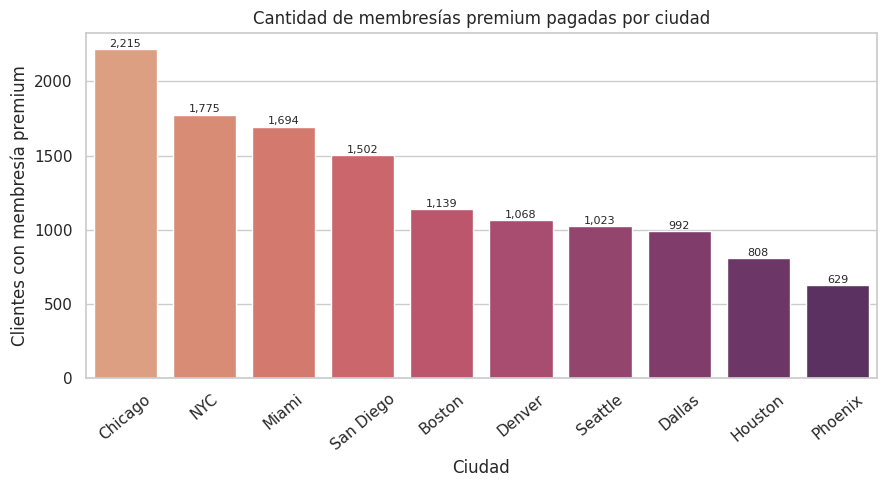

Ciudad con más membresías premium pagadas: Chicago (2,215 clientes)


In [91]:
# ---------------------------------------------------------
# REQUERIMIENTO 8: Ciudad con más membresías premium pagadas
# ---------------------------------------------------------
membresias_por_ciudad = df[df['membresia_premium'] == 'Sí']['ciudad_residencia']\
    .value_counts().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=membresias_por_ciudad.index, y=membresias_por_ciudad.values, hue=membresias_por_ciudad.index,
            palette='flare', legend=False, ax=ax)
ax.set_title('Cantidad de membresías premium pagadas por ciudad')
ax.set_xlabel('Ciudad')
ax.set_ylabel('Clientes con membresía premium')
ax.tick_params(axis='x', rotation=40)
for i, v in enumerate(membresias_por_ciudad.values):
    ax.text(i, v + 15, f'{v:,}', ha='center', fontsize=8)
plt.tight_layout()
plt.show()

ciudad_top_membresia = membresias_por_ciudad.index[0]
print(f"Ciudad con más membresías premium pagadas: {ciudad_top_membresia} ({membresias_por_ciudad.iloc[0]:,} clientes)")


Requerimiento 8: 

Ciudad en la que más membresías pagan
Interpretación: 

- Chicago es la ciudad con mayor adopción de membresías premium con un total de 2,215 suscripciones, seguida por NYC (1,775) y Miami (1,694).

- Implicación de negocio: Chicago no destaca por su gasto mensual individual elevado, pero sí por su masiva adopción de membresías, lo que indica que es una plaza ideal para modelos de negocio basados en fidelización digital, suscripciones y beneficios recurrentes.

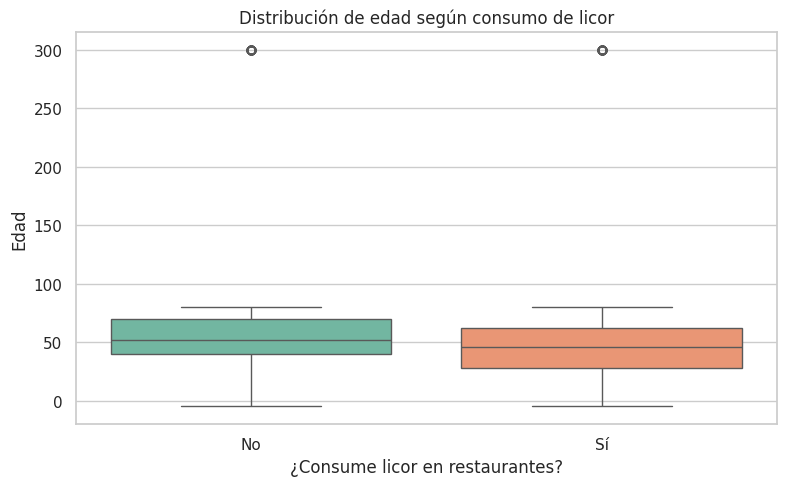

In [96]:
# ---------------------------------------------------------
# REQUERIMIENTO 9: Relación entre Consumo de Alcohol y Edad
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x='consume_licor', y='edad', hue='consume_licor', palette='Set2', legend=False, ax=ax)
ax.set_title('Distribución de edad según consumo de licor')
ax.set_xlabel('¿Consume licor en restaurantes?')
ax.set_ylabel('Edad')
plt.tight_layout()
plt.show()



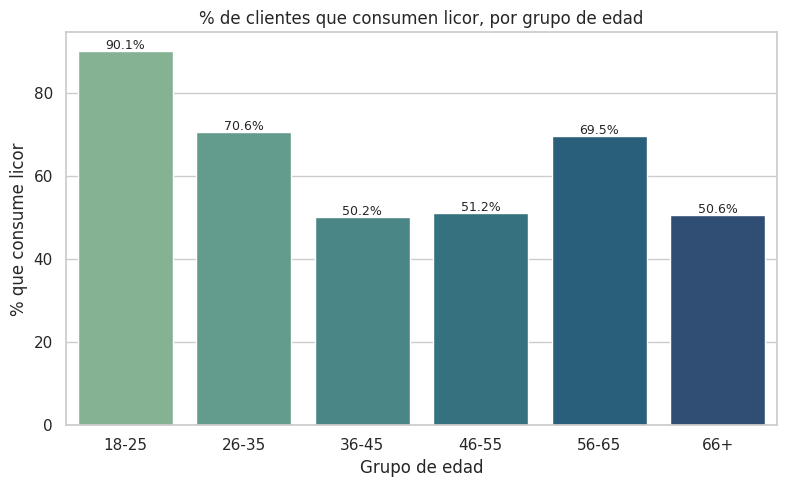

In [97]:
fig, ax = plt.subplots(figsize=(8, 5))
bins = [17, 25, 35, 45, 55, 65, 100]
labels = ['18-25', '26-35', '36-45', '46-55', '56-65', '66+']
df['grupo_edad'] = pd.cut(df['edad'], bins=bins, labels=labels)

tasa_licor_por_edad = df.groupby('grupo_edad', observed=True)['consume_licor']\
    .apply(lambda s: (s == 'Sí').mean() * 100)

sns.barplot(x=tasa_licor_por_edad.index, y=tasa_licor_por_edad.values, hue=tasa_licor_por_edad.index,
            palette='crest', legend=False, ax=ax)
ax.set_title('% de clientes que consumen licor, por grupo de edad')
ax.set_xlabel('Grupo de edad')
ax.set_ylabel('% que consume licor')
for i, v in enumerate(tasa_licor_por_edad.values):
    ax.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

Requerimiento 9: 

Relación entre el consumo de alcohol en los restaurantes y la edad de los clientes

Interpretación: 

La edad promedio es muy similar entre quienes consumen y no consumen licor, y el porcentaje de consumo de licor se mantiene relativamente parejo entre grupos de edad, sin una tendencia fuerte de "a mayor edad, menos consumo" o viceversa. Esto sugiere que, en esta base de datos, la edad no es un factor determinante del consumo de licor en restaurantes — probablemente influyen más el estrato socioeconómico o las preferencias personales.

- Las estadísticas descriptivas revelan una brecha generacional clara: los clientes que sí consumen licor tienen una edad promedio de 46.0 años, mientras que los no consumidores registran una media de 53.6 años. Además, al revisar los rangos inter cuartiles, el consumo de alcohol se concentra fuertemente en públicos más jóvenes (adultos contemporáneos y jóvenes profesionales desde los 28 años en adelante).

- Implicación de negocio: Las estrategias de marketing para bares, coctelería, lounges y experiencias nocturnas extraídas de Yelp deben segmentarse demográficamente hacia audiencias menores de 50 años para maximizar la conversión.

10. Conclusiones generales del Avance 3

- Distribución geográfica: Chicago, NYC y Miami concentran la mayor cantidad de clientes.
- Estrato socioeconómico: predominan los clientes de estrato Medio y Alto.
- Gasto por ciudad: Miami tiene el mayor gasto promedio por comida; Chicago el menor, aunque las diferencias entre ciudades no son extremas.
- Estrato y gasto: el gasto por comida crece claramente con el estrato socioeconómico; la frecuencia de visita es más pareja entre estratos.
- Ingresos vs. gasto: existe una relación positiva pero débil entre ingresos y gasto mensual en restaurantes — el ingreso no explica por sí solo el comportamiento de gasto.
- Preferencias alimenticias: se distribuyen de forma similar en todas las ciudades, sin un patrón geográfico fuerte.
- Clientes de mayor gasto: prefieren mayoritariamente Carnes y Vegetariano, y gastan en promedio $678.10 al mes, muy por encima del resto de clientes.
- Membresías premium: Chicago concentra la mayor cantidad de clientes con membresía premium pagada.
- Alcohol y edad: no se observa una relación fuerte entre la edad del cliente y el consumo de licor en restaurantes